In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()

/Users/sagarrudagi/Desktop/Learning/Coding - Projects/NLP Learning/lcm/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
/Users/sagarrudagi/Desktop/Learning/Coding - Projects/NLP Learning/lcm/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
model = ChatOpenAI(model="gpt-4o-mini")

In [3]:
class BlogState(TypedDict):
    title: str
    outline: str
    blog: str

In [4]:
def create_outline(state: BlogState) -> BlogState:
    title = state["title"]
    prompt = f"Create an outline for a blog with the title: {title}"
    state["outline"] = model.invoke(prompt).content
    return state

In [5]:
def create_blog(state: BlogState) -> BlogState:
    title = state["title"]
    outline = state["outline"]
    prompt = f"Write a blog with the title: {title} and the outline: {outline}"
    state["blog"] = model.invoke(prompt).content
    return state

In [8]:
# Create graph
graph = StateGraph(BlogState)

# Add nodes
graph.add_node("create_outline", create_outline)
graph.add_node("create_blog", create_blog)

# Add edges
graph.add_edge(START, "create_outline")
graph.add_edge("create_outline", "create_blog")
graph.add_edge("create_blog", END)

# Compile graph
workflow = graph.compile()

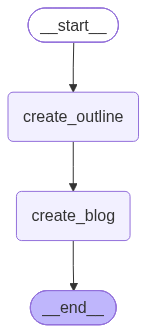

In [9]:
workflow

In [10]:
final_state = workflow.invoke({"title": "Artificial Intelligence is the way forward"})
print(final_state["blog"])

# Artificial Intelligence is the Way Forward

---

### I. Introduction

#### A. Hook: The transformative power of AI in today's world
We are living in an era where technology is reshaping our lives at an unprecedented pace. From virtual assistants that manage our daily schedules to advanced algorithms diagnosing diseases faster than human doctors, artificial intelligence (AI) is not just a buzzword; it is a revolutionary force that is fundamentally changing the landscape of various industries.

#### B. Brief overview of AI's evolution
Artificial Intelligence has come a long way since its inception in the mid-20th century. Over the last few decades, it has transitioned from theoretical constructs in academia to practical applications integral to our daily lives. The evolution of AI technologies, such as machine learning and neural networks, has made it possible to create systems that learn and adapt, opening the doors to a myriad of opportunities.

#### C. Purpose of the blog: To explor